# Neural-network evaluation and diagnostics

This undergraduate project compares event-selection cuts and neural networks using university-provided simulated data. The notebook presents completed analysis and selected historical results.

The data and provided helper implementations are not redistributed. Their roles are explained where they affect the analysis. Selected code illustrates my project logic; full reproducibility is not claimed. Read the saved outputs without running all cells, which would clear the historical output archive.

See the [project overview](../README.md) and [provenance](../PROVENANCE.md). This is an independent project, not an official ATLAS analysis.


Explicit imports support the retained project excerpts. No wildcard or provided-helper import remains.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import random
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense


The historical evaluation used the supplied training, validation and test splits. The CSV loading code and datasets are omitted. Final NN reporting used the test split, but the cut thresholds had been tuned on the combined dataset including test events.

## Historical cut-versus-NN comparison

These results share the same test sample, but do not constitute a strictly untouched-test comparison because the cut benchmark was tuned using combined data.

The implemented cut benchmark used `Mtop > 200 GeV` and `dRBB < 1.45`. `sensitivity_cut_based` scored weighted mBB bins; `plot_variable` rendered before/after histograms. The university-provided resources, baseline reporting scaffolding and helper plots are omitted; saved aggregate scores are retained.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only


Sensitivity achieved before cuts  1.4956892137142674
Sensitivity achieved after cuts  1.8782041819509867


## Selected neural network

The five inputs were dRBB, mBB, MET, Mtop and pTV. The omitted `scale_prepare_data` helper fitted standard scaling to training data, transformed validation/test features and extracted labels and training weights. No replacement is supplied.

The final model architecture below is a rewritten description in code of the selected [16, 8] classifier. Its dense binary-classifier structure is adapted provided baseline methodology; the selected configuration arose from my optimisation study. It constructs a model only and performs no training.

In [ ]:
def classifier(variables):
    """Selected configuration; dense-classifier pattern adapted from provided baseline methodology."""
    model = Sequential([
        Input(shape=(len(variables),)),
        Dense(16, activation="relu"),
        Dense(8, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


Historically the selected model was trained with supplied sample weights, validation data, 20 epochs and batch size 64. The training invocation and log are omitted.

The individual test run scored about 2.27 with approximately 0.02 propagated uncertainty from the omitted `sensitivity_NN` helper. The `nn_output_plot` image with inherited "ATLAS Internal" is omitted.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



A sensitivity of 2.27 ± 0.02 was achieved


The historical project seed-setting function is retained unchanged. Hash assignment inside the running interpreter and TensorFlow seed-setting do not guarantee full determinism.

In [ ]:
def set_all_seeds(seed):
    """
    Set random seeds for reproducible sampling and model training.

    Parameters
    ----------
    seed : int
        Seed applied to Python, NumPy, TensorFlow, and the Python hash
        environment variable.

    Returns
    -------
    None
        The function updates global random-state settings in place.
    """
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

The test comparison was repeated across seeds [11, 22, 33, 44, 55], with model-training seeds reset in each run. The saved result is **2.271 ± 0.026**, where 0.026 is the **sample standard deviation** (`ddof=1`) across retrainings. It is distinct from the approximately 0.02 propagated uncertainty of the individual run. Training and provided-evaluator calls are omitted.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



Mean sensitivity = 2.271
Std sensitivity  = 0.026


## Training-sample statistics

I varied the retained signal and background fractions separately and compared validation sensitivity. These are completed historical experiments, not experiments rerun for this portfolio.

My subsampling function below independently selects signal and background events and optionally shuffles the combined subset. The historical function retains at least one event per class; it does not test a true zero-event fraction. No data are included or passed to it here.

In [ ]:
def make_reduced_train_df(df_train, sig_frac=1.0, bkg_frac=1.0, seed=42, shuffle=True):
    """
    Create a reduced training sample with independently controlled
    signal and background fractions.

    Parameters
    ----------
    df_train : pandas.DataFrame
        Full training dataframe containing both signal and background events.
    sig_frac : float, optional
        Fraction of signal events (Class == 1) to retain.
    bkg_frac : float, optional
        Fraction of background events (Class == 0) to retain.
    seed : int, optional
        Random seed used for reproducible subsampling.
    shuffle : bool, optional
        If True, shuffle the reduced dataframe before returning it.

    Returns
    -------
    pandas.DataFrame
        Reduced training dataframe containing the selected fractions of
        signal and background events.
    """
    rng = np.random.default_rng(seed)
    # separate signal and background
    df_sig = df_train[df_train["Class"] == 1].copy()
    df_bkg = df_train[df_train["Class"] == 0].copy()

    # fraction to keep 
    n_sig_keep = max(1, int(len(df_sig) * sig_frac))
    n_bkg_keep = max(1, int(len(df_bkg) * bkg_frac))
    
    sig_idx = rng.choice(df_sig.index, size=n_sig_keep, replace=False)
    bkg_idx = rng.choice(df_bkg.index, size=n_bkg_keep, replace=False)

    # subset
    df_sig_sub = df_sig.loc[sig_idx]
    df_bkg_sub = df_bkg.loc[bkg_idx]
    
    df_sub = pd.concat([df_sig_sub, df_bkg_sub], axis=0)

    if shuffle:
        df_sub = df_sub.sample(frac=1.0, random_state=seed)
    
    return df_sub.reset_index(drop=True)

The subsampling study reused the university-provided training data; the redundant loading cell and the CSV are omitted.

The broad scan used fractions [0.01, 0.02, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0] and sampling seeds [11, 22, 33, 44, 55].

**Seeding limitation:** these loops seeded subsampling and shuffling but did not reset model-training seeds inside each fraction/seed iteration. Results depend on the evolving model RNG state and execution order. Their spreads combine sampling and training variation; the rows are not fully controlled paired training-seed experiments.

### Retained signal fraction

I varied signal fraction with all background events retained, retraining at 20 epochs and batch size 64. The omitted `scale_prepare_data`, `sensitivity_NN` and `mean_std_sensitivity(drop=0)` helpers supplied scaling, scoring, and the mean/population-standard-deviation summary. Only the saved aggregate fraction table is retained; training logs and per-run tables are removed.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



   signal_fraction  background_fraction  mean_sensitivity  std_sensitivity  \
0             0.01                  1.0          0.915315         0.023984   
1             0.02                  1.0          0.966727         0.045720   
2             0.05                  1.0          0.999987         0.016936   
3             0.10                  1.0          1.033494         0.040161   
4             0.20                  1.0          1.056336         0.055649   
5             0.40                  1.0          1.038617         0.027433   
6             0.60                  1.0          1.029582         0.011960   
7             0.80                  1.0          1.020439         0.029397   
8             1.00                  1.0          1.005015         0.029150   

   min_sensitivity  max_sensitivity  
0         0.871569         0.942663  
1         0.891997         1.011489  
2         0.979793         1.025198  
3         0.995339         1.084402  
4         0.982314         1.

### Retained background fraction

I varied background fraction with all signal events retained using the same historical scaling, scoring and summary helpers. Only the saved aggregate fraction table is retained.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



   signal_fraction  background_fraction  mean_sensitivity  std_sensitivity  \
0              1.0                 0.01          0.646979         0.046194   
1              1.0                 0.02          0.763744         0.037770   
2              1.0                 0.05          0.882184         0.048126   
3              1.0                 0.10          0.958293         0.067595   
4              1.0                 0.20          0.984069         0.022307   
5              1.0                 0.40          1.024393         0.036878   
6              1.0                 0.60          0.981697         0.018482   
7              1.0                 0.80          0.987951         0.030313   
8              1.0                 1.00          1.020515         0.021863   

   min_sensitivity  max_sensitivity  
0         0.571369         0.716341  
1         0.699725         0.803875  
2         0.800886         0.945591  
3         0.895685         1.050769  
4         0.959559         1.

Historical broad fraction-scan figure and my plotting excerpt. Blue varies signal with full background; orange varies background with full signal. The historical aggregate summary tables are not regenerated. Error bars are population standard deviations across the historical repeats, subject to the seeding limitation above.

Illustrative historical plotting excerpt (not executed; aggregate tables are not reconstructed):

```python
# plot sensitivity variation with training fraction of signal and background together 
plt.figure(figsize=(7,5))

plt.errorbar(
    summary_df_sigfrac['signal_fraction'],
    summary_df_sigfrac['mean_sensitivity'],
    yerr=summary_df_sigfrac['std_sensitivity'],
    fmt='o-',
    capsize=4,
    label='Vary signal, keep background = 100%'
)

plt.errorbar(
    summary_df_bkgfrac['background_fraction'],
    summary_df_bkgfrac['mean_sensitivity'],
    yerr=summary_df_bkgfrac['std_sensitivity'],
    fmt='s-',
    capsize=4,
    label='Vary background, keep signal = 100%'
)

# plt.xscale('log')
plt.xlabel('Training fraction')
plt.ylabel('Validation sensitivity')
plt.title('Sensitivity vs training statistics')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()
```

**Saved historical output; not regenerated for this portfolio.** 

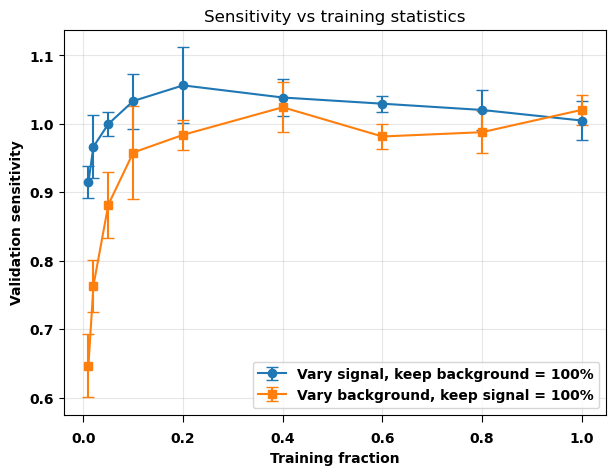

In [ ]:
# Historical output archive; display only



Sensitivity rose quickly with signal statistics and plateaued early. Background statistics had a stronger effect over a wider range. These observations describe the saved experiments and do not establish exact plateau locations.

The background-focused follow-up used fractions [0.1, 0.2, 0.4, 0.6, 0.8, 1.0] and ten sampling seeds [11, 22, 33, 44, 55, 66, 77, 88, 99, 111]. It had the same model-training-seed limitation.

The follow-up repeated background-fraction training and retained the aggregate summary produced through the same omitted scaling, sensitivity and mean/spread helpers.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



   signal_fraction  background_fraction  mean_sensitivity  std_sensitivity  \
0              1.0                  0.1          0.935818         0.028859   
1              1.0                  0.2          0.999732         0.024677   
2              1.0                  0.4          1.023301         0.042886   
3              1.0                  0.6          1.007704         0.029656   
4              1.0                  0.8          1.026950         0.024836   
5              1.0                  1.0          1.006101         0.034940   

   min_sensitivity  max_sensitivity  
0         0.898451         1.002490  
1         0.951420         1.031400  
2         0.934482         1.083829  
3         0.947491         1.040095  
4         0.978287         1.059676  
5         0.940735         1.043289  


Historical background-focused figure and plotting excerpt. It combines the original five-repeat signal scan with the ten-repeat background follow-up; these are not identically repeated paired series.

Illustrative historical plotting excerpt (not executed; aggregate tables are not reconstructed):

```python
# plot sensitivity variation with training fraction of signal and background together, with the updated bkg frac (focusing on higher frac)
plt.figure(figsize=(7,5))

plt.errorbar(
    summary_df_sigfrac['signal_fraction'],
    summary_df_sigfrac['mean_sensitivity'],
    yerr=summary_df_sigfrac['std_sensitivity'],
    fmt='o-',
    capsize=4,
    label='Vary signal, keep background = 100%'
)

plt.errorbar(
    summary_df_bkgfrac['background_fraction'],
    summary_df_bkgfrac['mean_sensitivity'],
    yerr=summary_df_bkgfrac['std_sensitivity'],
    fmt='s-',
    capsize=4,
    label='Vary background, keep signal = 100%'
)

# plt.xscale('log')
plt.xlabel('Training fraction')
plt.ylabel('Validation sensitivity')
plt.title('Sensitivity vs training statistics')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()
```

**Saved historical output; not regenerated for this portfolio.** 

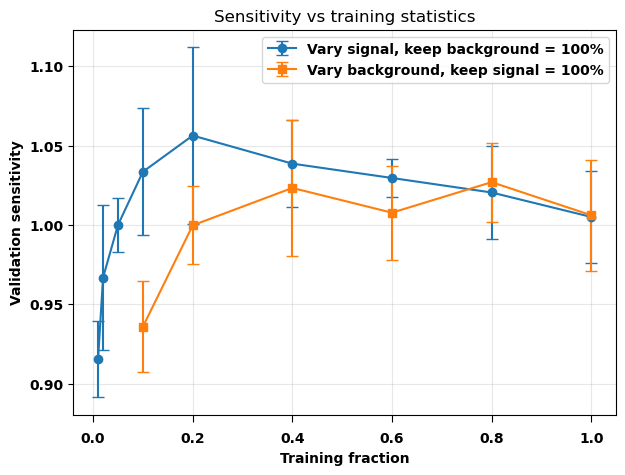

In [ ]:
# Historical output archive; display only



Above approximately 0.4 retained background fraction, the means changed little compared with the observed spread. This is a descriptive plateau in the saved scan.

## Variable-removal study

For each feature subset, my historical scan rebuilt and retrained the selected network with model-training seeds reset per run. It used the omitted provided scaler, NN sensitivity evaluator and mean/population-standard-deviation summariser. The helper-dependent orchestration is replaced by this explanation.

I compared the full five-input model with one variable removed at a time across seeds [11, 22, 33, 44, 55], using 20 epochs and batch size 64. The aggregate comparison is presented once in the following cell; duplicate run logs and summary output are omitted here.

The drop is the full-model mean minus each reduced-model mean. The saved table is aggregate experiment output, not event data.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



                variables_used  n_variables removed_variable  \
0       (dRBB, MET, Mtop, pTV)            4              mBB   
1        (mBB, MET, Mtop, pTV)            4             dRBB   
2       (dRBB, mBB, MET, Mtop)            4              pTV   
3       (dRBB, mBB, Mtop, pTV)            4              MET   
4        (dRBB, mBB, MET, pTV)            4             Mtop   
5  (dRBB, mBB, MET, Mtop, pTV)            5             None   

   mean_sensitivity  std_sensitivity  min_sensitivity  max_sensitivity  \
0          0.876310         0.023564         0.839301         0.898166   
1          0.992170         0.012656         0.979605         1.015960   
2          1.003435         0.015728         0.989228         1.025545   
3          1.006770         0.020688         0.979412         1.031838   
4          1.033547         0.027010         0.986003         1.068489   
5          1.048995         0.016580         1.028361         1.073355   

   sensitivity_drop  
0         

Historical variable-removal figure and my plotting excerpt. Its error bars combine the two run-to-run population standard deviations in quadrature; they are not standard errors of the mean and do not account for covariance between paired seeds.

Illustrative historical plotting excerpt (not executed; aggregate tables are not reconstructed):

```python
# plot drop in sensitivity for each variable 

full_model_std = summary_df_lovo.loc[
    summary_df_lovo['removed_variable'] == 'None',
    'std_sensitivity'
].iloc[0]

plot_df = summary_df_lovo[summary_df_lovo['removed_variable'] != 'None'].copy()
plot_df = plot_df.sort_values('sensitivity_drop', ascending=False)
# uncertainty also need to consider the deviation in baseline model (full variables)
plot_df['drop_uncertainty'] = np.sqrt(full_model_std**2 + plot_df['std_sensitivity']**2)

plt.figure(figsize=(7,5))
plt.bar(
    plot_df['removed_variable'],
    plot_df['sensitivity_drop'],
    yerr=plot_df['drop_uncertainty'],
    capsize=4
)
plt.xlabel('Removed variable')
plt.ylabel('Drop in mean validation sensitivity')
plt.title('Leave-one-variable-out retraining importance')
plt.grid(True, axis='y', alpha=0.3)
plt.show()
```

**Saved historical output; not regenerated for this portfolio.** 

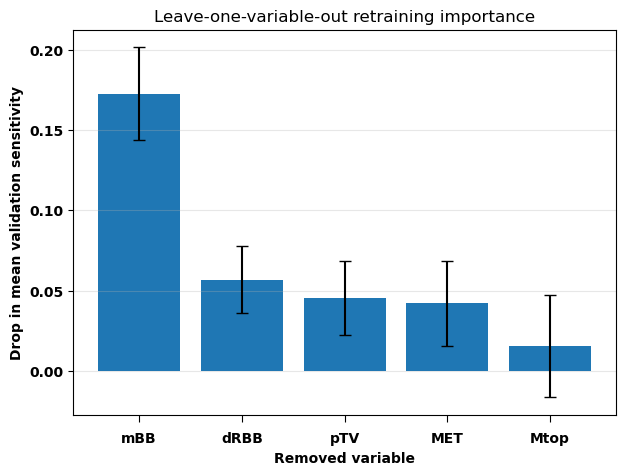

In [ ]:
# Historical output archive; display only



Removing mBB caused the largest sensitivity loss (about 0.173). The other variables had smaller effects; their ordering should not be over-interpreted relative to the observed spread.

## Training uncertainty

The fixed-data training-uncertainty experiment used model-training seeds [11, 22, 33, 44, 55, 66, 77, 88, 99, 111].

With all training events kept fixed, I reset the model-training seeds before each retraining. Historical scaling and sensitivity evaluation used omitted provided helpers. The summary mean 1.032560 and population standard deviation 0.022353 are retained below; the training loop and per-run listing are omitted.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



   mean_sensitivity  std_sensitivity  min_sensitivity  max_sensitivity  n_runs
0           1.03256         0.022353         0.994507         1.073355      10


Historical fixed-data retraining scatter and plotting excerpt. Each point is an aggregate validation sensitivity from one training, not an event record.

Illustrative historical plotting excerpt (not executed; aggregate tables are not reconstructed):

```python
# plot the scatter 
plt.figure(figsize=(7,5))
plt.plot(runs_df_unc['seed'], runs_df_unc['sensitivity'], 'o')
plt.axhline(mean_sens_unc, linestyle='--', label=f"Mean = {mean_sens_unc:.3f}")
plt.xlabel('Seed')
plt.ylabel('Validation sensitivity')
plt.title('Deviation across retrainings')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()
```

**Saved historical output; not regenerated for this portfolio.** 

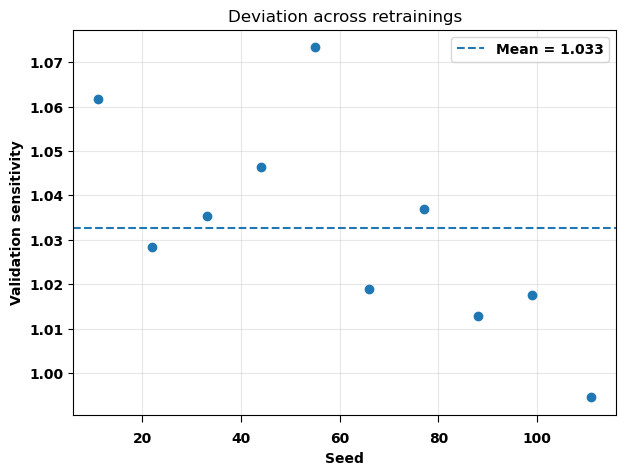

In [ ]:
# Historical output archive; display only



Training stochasticity produced a measurable validation spread.

## High-score-region study

My historical `nn_bin_contributions` extension obtained adaptive edges from the omitted `trafoD_with_error` provided helper, then summed weighted signal/background yields by score bin, calculated the same binned significance contributions, and accumulated the fraction of total squared sensitivity. That provided helper and its implementation are not redistributed. The dependent function is replaced by this description, not reimplemented.

The saved contribution table is aggregate score-bin output. In the original execution sequence, this diagnostic used the model left by the fixed-data uncertainty loop (seed 111), rather than the earlier representative test run. Binning follows the historical provided helper; no new score-domain or binning implementation is asserted.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



     bin_low  bin_high   bin_mid  signal_yield  background_yield    purity  \
0   0.975976  1.000000  0.987988      0.889763          1.727888  0.339909   
1   0.967968  0.975976  0.971972      0.739682          2.787016  0.209738   
2   0.959960  0.967968  0.963964      0.706236          2.982202  0.191473   
3   0.947948  0.959960  0.953954      0.706982          5.615138  0.111827   
4   0.929930  0.947948  0.938939      0.732255          7.682267  0.087023   
5   0.903904  0.929930  0.916917      0.652971         10.515691  0.058465   
6   0.867868  0.903904  0.885886      0.621124         13.302897  0.044608   
7   0.823824  0.867868  0.845846      0.557166         19.327929  0.028019   
8   0.767768  0.823824  0.795796      0.491679         24.733187  0.019492   
9   0.673674  0.767768  0.720721      0.431333         31.370738  0.013563   
10  0.509510  0.673674  0.591592      0.353832         38.072493  0.009208   
11  0.315315  0.509510  0.412412      0.210004         51.637590

Historical contribution figure and plotting excerpt. Contributions are to squared sensitivity, not percentages of event counts. The fixed bar width of 0.05 was a visual choice even though the historical bins have unequal widths.

Illustrative historical plotting excerpt (not executed; aggregate tables are not reconstructed):

```python
# plot results 
plt.figure(figsize=(8,5))
plt.bar(contrib_df['bin_mid'], contrib_df['sens_contrib_sq'], width=0.05)
plt.xlabel('NN output bin centre')
plt.ylabel('Sensitivity contribution squared')
plt.title('Bin-by-bin contribution to total sensitivity')
plt.grid(True, axis='y', alpha=0.3)
plt.show()
```

**Saved historical output; not regenerated for this portfolio.** 

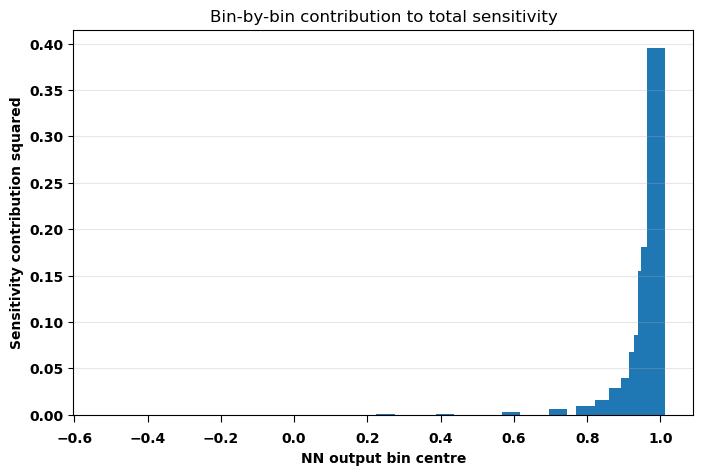

In [ ]:
# Historical output archive; display only



Starting from the highest score bin, I included bins through the first crossing of 50% of total squared sensitivity. The saved threshold was approximately 0.967968. It is a diagnostic threshold on validation data, not a new test-set optimisation.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



Chosen high-output threshold: 0.967967967967968


The historical high-score region selected validation events with score at least the saved threshold. No selected event rows or indices are retained.

Saved aggregate weighted yields and purity for the high-score validation region.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



High-output region threshold: 0.967967967967968
Signal yield: 1.6294452610454746
Background yield: 4.514904448997851
Purity: 0.2651940950532233


## Historical overlap diagnostic

This diagnostic used `Mtop > 200 GeV` and **`dRBB < 1.4`**, whereas the final cut benchmark used **`dRBB < 1.45`**. The overlap results below must not be presented as measurements for the identical final cut.

The historical overlap reference region used the stricter separation threshold 1.4. That historical choice is documented without rerunning or silently substituting 1.45.

Only the aggregate intersection count and overlap fractions are retained. Event identifiers and selected-event indices are omitted.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



Overlap events: 2787
Fraction of high-NN events also in cut-based: 0.9982091690544412
Fraction of cut-based events also in high-NN: 0.28687596500257334


My weighted region-summary function is retained as an illustrative aggregate-reporting function. It is not called on university-provided data here.

In [ ]:
def region_summary(df, name):
    """
    Print a short weighted-yield summary for a selected event region.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataframe containing the selected events, with 'Class' and
        'EventWeight' columns.
    name : str
        Label used when printing the summary.

    Returns
    -------
    None
        The function prints the weighted signal yield, background yield,
        and purity for the supplied region.
    """
    S = df.loc[df['Class'] == 1, 'EventWeight'].sum()
    B = df.loc[df['Class'] == 0, 'EventWeight'].sum()
    print(name)
    print("  S =", S)
    print("  B =", B)
    print("  purity =", S / (S + B))
    print()

Saved aggregate region summaries; the cut-based reference here uses separation threshold 1.4, not 1.45.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



High NN output region
  S = 1.6294452610454746
  B = 4.514904448997851
  purity = 0.2651940950532233

Cut-based selected region
  S = 5.048656852357892
  B = 155.3734935263215
  purity = 0.03147107079939052



## Interpretation

About 99.8% of the high-score validation events also satisfied the historical 1.4 cut region, while about 28.7% of that cut region was in the high-score subset. This model selected a purer core within that reference region. These descriptive validation results do not demonstrate that all NN configurations select the same region. The overall cut-versus-NN performance comparison remains subject to combined-data cut tuning.